In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv('final_dataset.csv')
df["gender"] = df["gender"].map({"male": 1, "female": 0})
excluded_columns = ["question_number",	"student_id",	"has_intro", "file_name"]  
features = df.drop(columns=excluded_columns)


In [5]:
features.describe()

,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,log_mel_1,log_mel_2,log_mel_3,log_mel_4,log_mel_5,log_mel_6,...,mfcc_12,mfcc_13,spectral_contrast_1,spectral_contrast_2,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_contrast_7,gender
count,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,...,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000
mean,0.054954,0.170976,1893.056793,1929.081328,-24.408357,-20.533612,-19.026207,-23.217894,-30.253764,-35.060643,...,-2.817423,-4.180447,17.667740,14.178068,19.442202,19.898673,22.756795,31.342683,31.292369,0.768575
std,0.055693,0.026658,1285.677087,414.365355,11.105592,10.241122,10.655355,11.713222,11.641152,10.884943,...,8.598965,9.469299,3.597710,2.438562,2.943168,2.643634,2.429598,4.304217,6.560196,0.422001
min,0.006679,0.001929,676.703972,1094.504697,-69.511160,-69.631996,-70.493220,-70.769890,-71.311760,-71.659270,...,-32.578854,-30.792100,6.134539,5.500055,7.212382,8.723677,14.126717,15.918311,13.496614,0.000000
25%,0.027361,0.164994,1240.350891,1642.914456,-30.456938,-24.566574,-22.241800,-28.678220,-37.371340,-41.897877,...,-8.758240,-10.399458,15.196449,12.764616,17.941771,18.356203,21.076658,28.461698,27.175248,1.000000
50%,0.035740,0.174484,1482.816332,1859.053958,-22.466913,-18.233969,-15.703797,-21.320694,-29.064032,-34.157158,...,-2.869582,-4.863769,18.348865,14.183379,19.654289,20.060046,22.618777,31.304603,30.850208,1.000000
75%,0.055541,0.184325,1934.814207,2125.475898,-16.285906,-13.515914,-12.299141,-14.575443,-21.959051,-27.073206,...,3.029158,1.903227,20.481872,15.682439,21.421342,21.611011,24.315244,34.211570,35.127551,1.000000
max,0.389508,0.255353,9404.544156,3828.028079,-4.265939,-5.610474,-4.974742,-5.276269,-7.448854,-10.938334,...,24.490343,29.624844,26.220016,22.694689,26.313290,29.945191,31.761034,44.890301,50.992761,1.000000


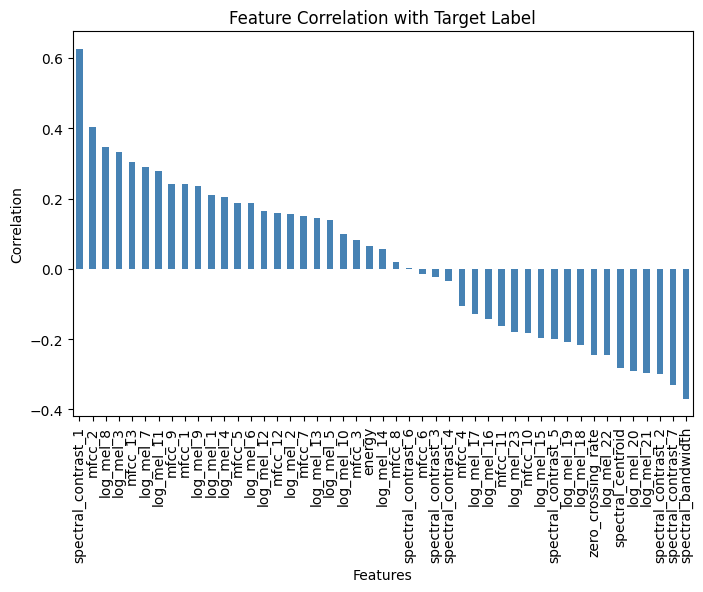

In [ ]:
label_correlation = features.corr()["gender"].drop("gender").sort_values(ascending=False)  # Replace "label" with your column name



In [ ]:
abs_correlation = label_correlation.abs()
abs_correlation = abs_correlation.sort_values(ascending=False)
# Plot bar chart
plt.figure(figsize=(8, 5))
abs_correlation.plot(kind="bar", color="steelblue")
plt.title("Feature Correlation with Target Label")
plt.xlabel("Features")
plt.ylabel("Correlation")
plt.xticks(rotation=90)
plt.show()


spectral_contrast_1    0.625671
mfcc_2                 0.403055
spectral_bandwidth     0.369842
log_mel_8              0.347623
log_mel_3              0.333319
spectral_contrast_7    0.331641
mfcc_13                0.303942
spectral_contrast_2    0.299457
log_mel_21             0.297115
log_mel_20             0.290034
log_mel_7              0.288464
spectral_centroid      0.282445
log_mel_11             0.279612
log_mel_22             0.246382
zero_crossing_rate     0.245591
mfcc_9                 0.240210
mfcc_1                 0.239917
log_mel_9              0.235224
log_mel_18             0.216878
log_mel_1              0.208870
log_mel_19             0.208528
log_mel_4              0.204362
spectral_contrast_5    0.200079
log_mel_15             0.197287
mfcc_5                 0.187302
log_mel_6              0.186417
mfcc_10                0.182372
log_mel_23             0.180840
log_mel_12             0.164267
mfcc_11                0.162897
mfcc_12                0.158091
log_mel_

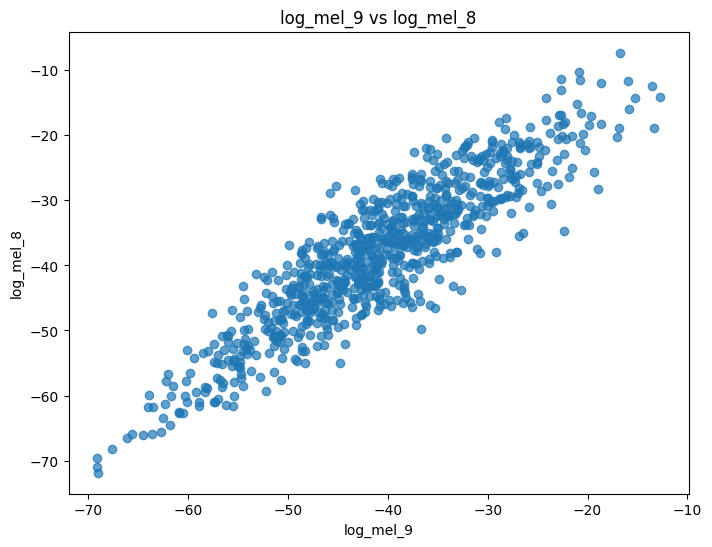

In [ ]:
feature_1 = "log_mel_9"
feature_2 = "log_mel_8"

plt.figure(figsize=(8, 6))
plt.scatter(df[feature_1], df[feature_2], alpha=0.7)
plt.xlabel(feature_1)
plt.ylabel(feature_2)
plt.title(f"{feature_1} vs {feature_2}")
plt.show()


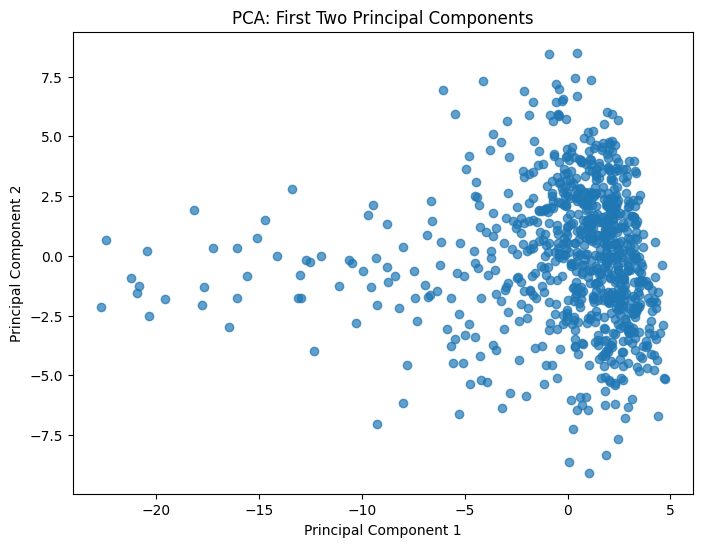

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_features)

df_pca = pd.DataFrame(principal_components, columns=["PC1", "PC2"])

plt.figure(figsize=(8, 6))
plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: First Two Principal Components")
plt.show()


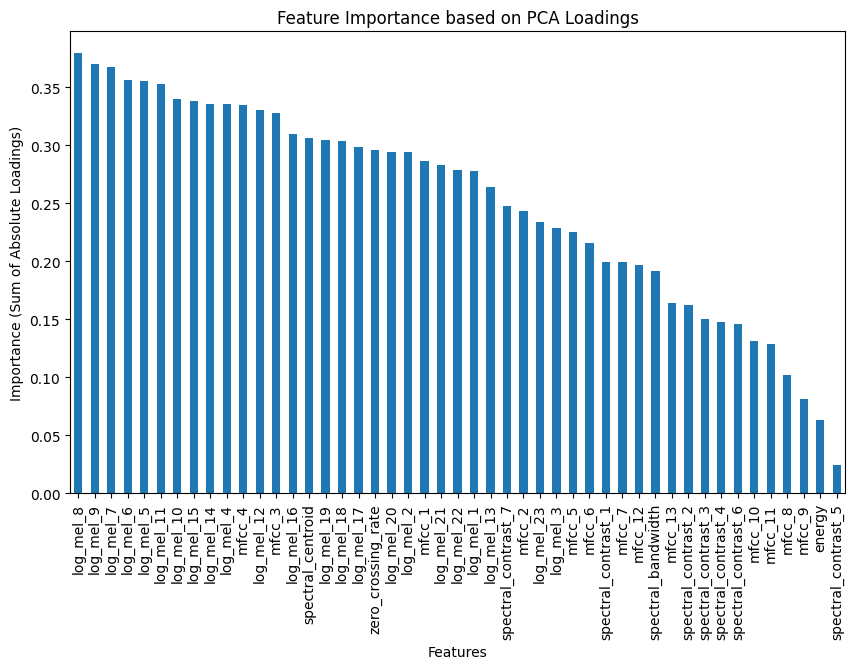

In [ ]:
import matplotlib.pyplot as plt

pca_loadings = pd.DataFrame(pca.components_, columns=features.columns, index=["PC1", "PC2"])
feature_importance = pca_loadings.abs().sum(axis=0).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feature_importance.plot(kind="bar")
plt.title("Feature Importance based on PCA Loadings")
plt.xlabel("Features")
plt.ylabel("Importance (Sum of Absolute Loadings)")
plt.xticks(rotation=90)
plt.show()


In [ ]:
import numpy as np

genders = df["gender"].unique()
colors = ["blue", "red"]

plt.figure(figsize=(8, 6))

for gender, color in zip(genders, colors):
    subset = df_pca[df_pca["gender"] == gender]
    plt.scatter(subset["PC1"], subset["PC2"], label=gender, color=color, alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Plot with Gender Coloring")
plt.legend(title="Gender")
plt.show()


KeyError: 'gender'

<Figure size 800x600 with 0 Axes>